# IA Não Supervisionada — Clusterização de Food Delivery

## 1. Introdução
Machine Learning Não Supervisionado procura padrões sem utilizar uma resposta previamente
rotulada para treinar o modelo. Clusterização reúne observações semelhantes segundo suas
características e uma medida de distância.

**Pergunta:** é possível identificar grupos de pedidos com perfis semelhantes de gasto,
desconto, logística e avaliação no mercado de Food Delivery?

Cada linha representa um pedido, não um cliente ou uma cidade. A base inclui entregas,
retiradas e consumo no local. O objetivo é explorar perfis de pedidos nesses canais.
O arquivo foi informado como proveniente do Kaggle; não há URL ou documentação de
coleta no projeto. O nome contém 2026, mas não existe coluna de data para confirmar
o período. Os campos enriquecidos não comprovam representatividade do mercado real.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Carregamento do dataset
O arquivo original permanece em `archive/`. O caminho é resolvido a partir da raiz
do projeto ou da pasta `notebooks`, sem depender de um caminho absoluto do computador.

In [7]:
nome_csv = "global_food_delivery_enriched_market_2026.csv"
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "archive" / nome_csv).is_file()), None)
if raiz is None:
    raise FileNotFoundError(f"Não foi encontrado archive/{nome_csv} nos diretórios ancestrais.")
caminho_csv = raiz / "archive" / nome_csv
df = pd.read_csv(caminho_csv)
print("CSV:", caminho_csv)
print(f"Dimensão: {df.shape[0]:,} linhas e {df.shape[1]} colunas")
print("Colunas:", df.columns.tolist())
display(df.head())

CSV: c:\Users\GUSTAVO\Documents\trabalhos facu\Mini projeto\archive\global_food_delivery_enriched_market_2026.csv
Dimensão: 8,000 linhas e 26 colunas
Colunas: ['order_id', 'metro_city', 'cuisine_category', 'order_channel', 'order_value_usd', 'discount_applied_usd', 'delivery_distance_km', 'estimated_prep_time_min', 'actual_delivery_time_min', 'delivery_fee_usd', 'customer_rating', 'restaurant_price_tier', 'is_peak_hour', 'weather_condition', 'net_effective_order_price', 'discount_percentage', 'delivery_speed_km_per_hr', 'total_fulfillment_time_min', 'delivery_fee_ratio', 'customer_spending_tier', 'logistics_friction_index', 'estimated_restaurant_net_margin_usd', 'customer_satisfaction_tier', 'primary_satisfaction_driver', 'cot_market_dynamics_rationale', 'confidence_score']


,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,customer_rating,restaurant_price_tier,is_peak_hour,weather_condition,net_effective_order_price,discount_percentage,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,3.5,$$ Moderate,False,Clear,22.82,0.00,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,4.0,$ Budget,True,Rainy,5.61,34.29,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,3.5,$$ Moderate,False,Clear,11.66,11.13,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,5.0,$ Budget,True,Clear,9.22,12.52,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,4.5,$$$ Premium / Fine Dining,False,Heavy Rain / Storm,115.42,7.46,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989


## 3. Análise exploratória dos dados
### 3.1 Estrutura, tipos e estatísticas

In [8]:
df.info()
display(df.dtypes.rename("Tipo").to_frame())
display(df.describe().round(3))
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = df.select_dtypes(include=["object", "string", "bool"]).columns.tolist()
print("Numéricas:", numericas)
print("Categóricas (incluindo booleanas):", categoricas)
print("Datas: não há coluna de data identificada no esquema do CSV.")

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   str    
 1   metro_city                           8000 non-null   str    
 2   cuisine_category                     8000 non-null   str    
 3   order_channel                        8000 non-null   str    
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 10  customer_rating                      8000 non-null   float64
 11  restaurant_price_tier                8000

,Tipo
order_id,str
metro_city,str
cuisine_category,str
order_channel,str
order_value_usd,float64
discount_applied_usd,float64
delivery_distance_km,float64
estimated_prep_time_min,int64
actual_delivery_time_min,float64
delivery_fee_usd,float64


,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,customer_rating,net_effective_order_price,discount_percentage,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,logistics_friction_index,estimated_restaurant_net_margin_usd,confidence_score
count,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000
mean,30.223,3.329,3.049,18.042,11.273,2.963,4.281,29.857,11.911,10.287,29.315,0.184,2.251,10.790,0.988
std,26.367,5.183,3.938,6.769,13.533,2.673,0.647,24.373,12.115,9.336,16.210,0.271,1.624,10.668,0.002
min,3.500,0.000,0.000,5.000,0.000,0.000,1.000,2.300,0.000,0.000,5.000,0.000,0.200,-0.210,0.953
25%,12.920,0.000,0.000,13.000,0.000,0.000,4.000,14.040,0.000,0.000,18.000,0.000,0.850,3.728,0.988
50%,21.705,1.530,1.600,18.000,8.000,2.970,4.500,22.310,9.535,10.500,26.000,0.101,2.190,7.440,0.989
75%,37.892,4.440,4.500,22.000,15.200,4.540,5.000,37.235,23.022,17.050,36.700,0.249,3.300,13.912,0.989
max,145.000,35.000,22.000,49.000,75.000,9.500,5.000,154.500,35.020,57.000,111.000,2.714,8.920,67.850,0.990


Numéricas: ['order_value_usd', 'discount_applied_usd', 'delivery_distance_km', 'estimated_prep_time_min', 'actual_delivery_time_min', 'delivery_fee_usd', 'customer_rating', 'net_effective_order_price', 'discount_percentage', 'delivery_speed_km_per_hr', 'total_fulfillment_time_min', 'delivery_fee_ratio', 'logistics_friction_index', 'estimated_restaurant_net_margin_usd', 'confidence_score']
Categóricas (incluindo booleanas): ['order_id', 'metro_city', 'cuisine_category', 'order_channel', 'restaurant_price_tier', 'is_peak_hour', 'weather_condition', 'customer_spending_tier', 'customer_satisfaction_tier', 'primary_satisfaction_driver', 'cot_market_dynamics_rationale']
Datas: não há coluna de data identificada no esquema do CSV.


### 3.2 Valores ausentes e duplicados

In [9]:
display(df.isna().sum().rename("Ausentes").to_frame())
print("Linhas inteiramente duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["order_id"].duplicated().sum())
display(df["order_channel"].value_counts().rename("Pedidos").to_frame())

,Ausentes
order_id,0
metro_city,0
cuisine_category,0
order_channel,0
order_value_usd,0
discount_applied_usd,0
delivery_distance_km,0
estimated_prep_time_min,0
actual_delivery_time_min,0
delivery_fee_usd,0


Linhas inteiramente duplicadas: 0
IDs repetidos: 0


,Pedidos
order_channel,
Online Delivery App,5255
Dine-In POS,1577
Takeaway / Pickup,1168


A base tem 8.000 pedidos, 26 colunas e 12 cidades. Não há valores ausentes,
linhas duplicadas ou IDs repetidos. Por isso, não é necessário imputar ou excluir
registros nesta base. Um gráfico de ausências não acrescentaria informação.
Há 5.255 pedidos por aplicativo, 1.577 de consumo no local e 1.168 retiradas.
Distâncias e tempos de entrega iguais a zero podem ser estruturais nesses últimos canais.

### 3.3 Distribuições das variáveis relevantes

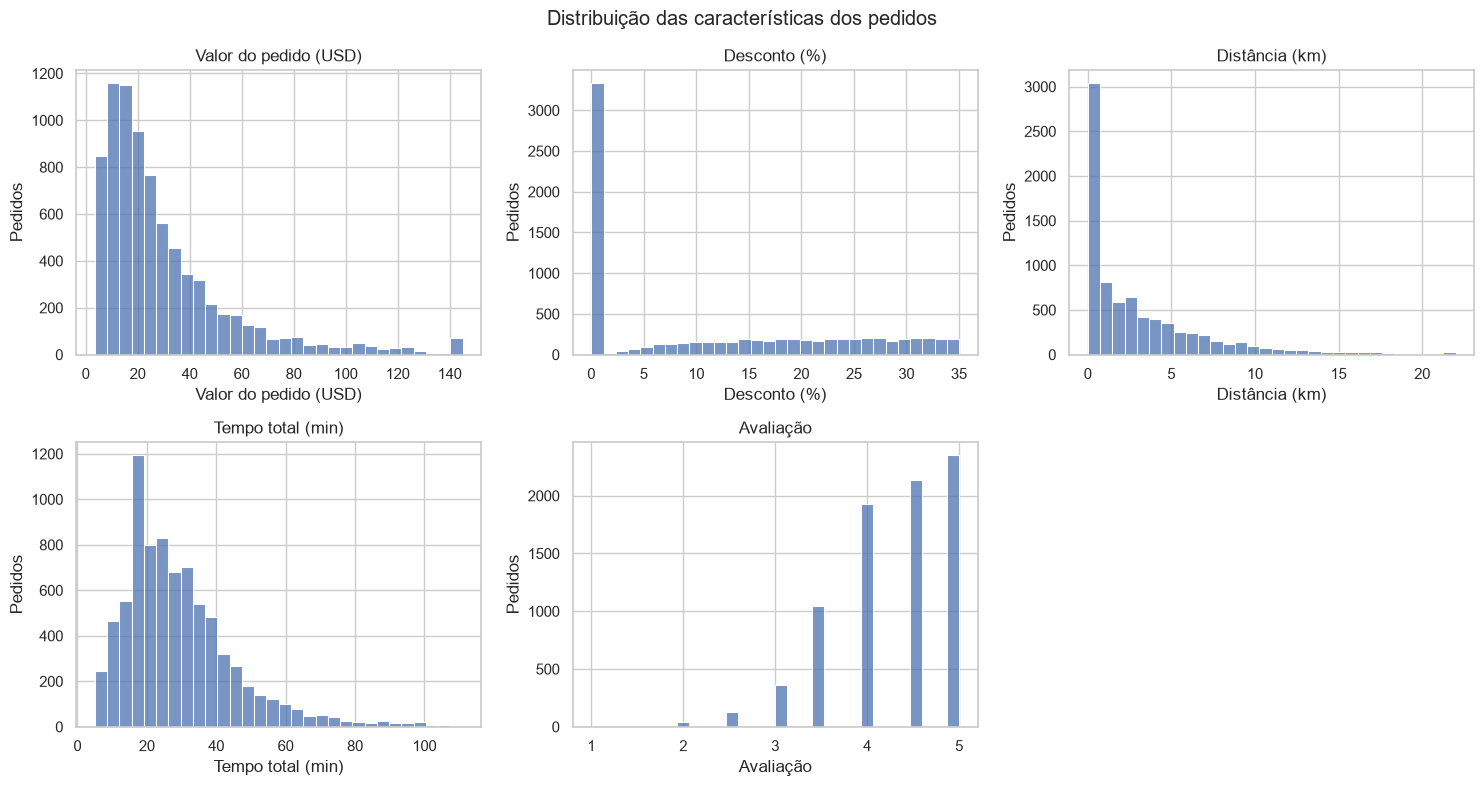

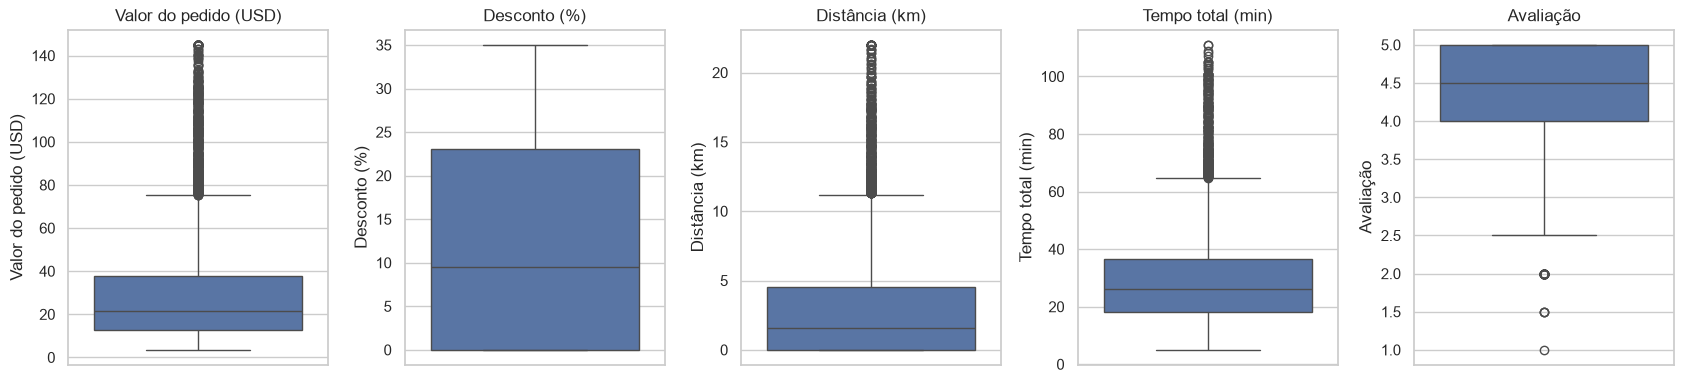

In [10]:
features = ["order_value_usd", "discount_percentage", "delivery_distance_km",
            "total_fulfillment_time_min", "customer_rating"]
rotulos = {"order_value_usd": "Valor do pedido (USD)",
           "discount_percentage": "Desconto (%)",
           "delivery_distance_km": "Distância (km)",
           "total_fulfillment_time_min": "Tempo total (min)",
           "customer_rating": "Avaliação"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, coluna in zip(axes.flat, features):
    sns.histplot(data=df, x=coluna, bins=30, ax=ax)
    ax.set(title=rotulos[coluna], xlabel=rotulos[coluna], ylabel="Pedidos")
axes.flat[-1].set_visible(False)
fig.suptitle("Distribuição das características dos pedidos")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, coluna in zip(axes, features):
    sns.boxplot(data=df, y=coluna, ax=ax)
    ax.set(title=rotulos[coluna], ylabel=rotulos[coluna])
plt.tight_layout()
plt.show()

O valor médio é US$ 30,22 e a mediana US$ 21,70: a cauda de valores altos eleva a média.
Os valores variam de US$ 3,50 a US$ 145,00. O desconto tem primeiro quartil zero
e mediana de 9,54%. A distância tem primeiro quartil zero e máximo de 22 km.
O tempo total vai de 5 a 111 minutos; a avaliação média é 4,28, em escala observada de 1 a 5.
Essas distribuições não são todas simétricas, o que limita a adequação de grupos esféricos.

### 3.4 Correlações

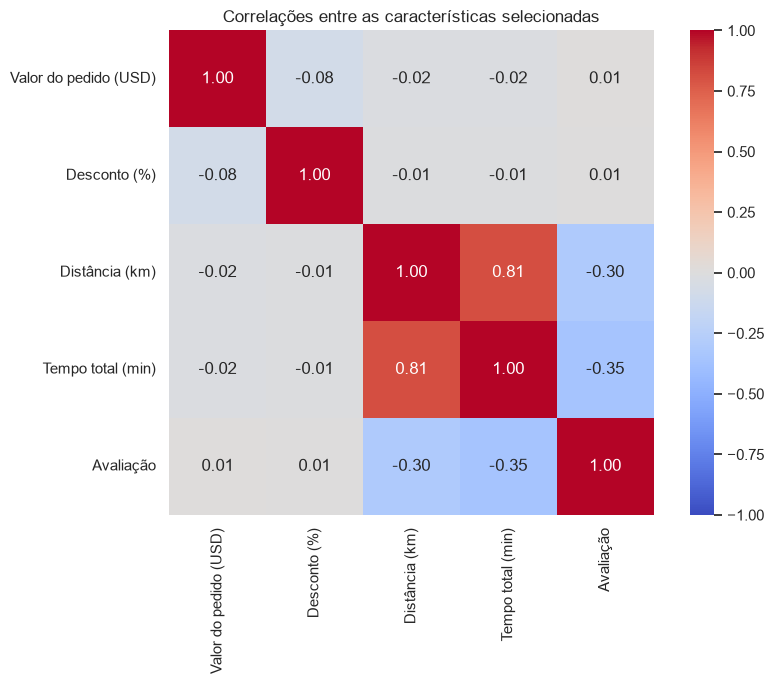

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[features].rename(columns=rotulos).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlações entre as características selecionadas")
plt.tight_layout()
plt.show()

Distância e tempo total apresentam correlação de aproximadamente 0,81.
Avaliação tem associação negativa com tempo total (−0,35) e distância (−0,30).
As demais correlações entre as variáveis selecionadas são fracas. Associação não
estabelece causalidade; distância e tempo darão peso conjunto à dimensão logística.

## 4. Preparação dos dados
### Seleção das features
- `order_value_usd`: dimensão econômica do pedido.
- `discount_percentage`: intensidade relativa de promoção, sem repetir o desconto absoluto.
- `delivery_distance_km`: alcance geográfico do atendimento.
- `total_fulfillment_time_min`: espera total, incluindo preparação e entrega.
- `customer_rating`: avaliação do pedido, utilizada como característica, sem prever rótulos.

Mantemos distância e tempo porque representam alcance e espera, embora correlacionados.
Não incluímos seus componentes e velocidade para evitar mais redundância. Taxa de entrega,
preço líquido e margem também podem repetir dimensões financeiras ou conter estimativas.
`order_id` identifica registros; cidade, culinária, clima, canal e horário de pico ficam
fora do cálculo para manter uma análise numérica simples. O canal será usado para interpretar.
As classificações de gasto e satisfação, o índice de fricção, o texto explicativo e
`confidence_score` são enriquecimentos cuja construção não foi documentada no projeto;
não os usamos como evidência independente nem como respostas supervisionadas.

### Ausências e outliers
O código remove apenas duplicatas integrais, se houver, e usa a mediana das features
caso surjam ausências em uma nova versão. Na base atual essas operações não mudam os dados.
O critério de 1,5 intervalo interquartil sinaliza extremos, sem provar que sejam erros.
Mantemos todos os extremos observados: podem representar pedidos caros ou viagens longas.

In [12]:
df_modelo = df.drop_duplicates().copy()
X = df_modelo[features].copy()
X = X.fillna(X.median())
if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Há valores não finitos nas features.")
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
extremos = (X.lt(q1 - 1.5 * iqr) | X.gt(q3 + 1.5 * iqr)).sum()
display(extremos.rename("Extremos pelo IQR (mantidos)").to_frame())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
display(pd.DataFrame(X_scaled, columns=features).agg(["mean", "std"]).round(3))

,Extremos pelo IQR (mantidos)
order_value_usd,558
discount_percentage,0
delivery_distance_km,389
total_fulfillment_time_min,308
customer_rating,44


,order_value_usd,discount_percentage,delivery_distance_km,total_fulfillment_time_min,customer_rating
mean,0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


O `StandardScaler` centraliza cada variável e ajusta sua escala pelo desvio padrão.
Assim, dólares e minutos não dominam a distância apenas por sua unidade.
Padronizar não elimina assimetrias nem reduz automaticamente a influência de outliers.

## 5. Definição do número de clusters
Testamos K de 2 a 10 com K-Means, semente 42 e dez inicializações.
A inércia mede dispersão interna e sempre tende a diminuir com K; o cotovelo é uma
avaliação visual. A silhouette compara coesão e separação (quanto mais próxima de 1, melhor).
Para reduzir custo, calculamos silhouette numa amostra fixa de até 2.000 pedidos,
com os rótulos dos modelos ajustados em todos os pedidos. A mesma amostra será usada
para comparar algoritmos. Isso torna a comparação consistente, mas aproximada.

,K,Inércia,Silhouette
0,2,29663.3142,0.3544
1,3,23950.1747,0.2514
2,4,19700.2264,0.2699
3,5,17466.0162,0.2404
4,6,15507.5812,0.2396
5,7,14229.5722,0.2360
6,8,13277.2531,0.2386
7,9,12571.1903,0.2313
8,10,11946.3259,0.2271


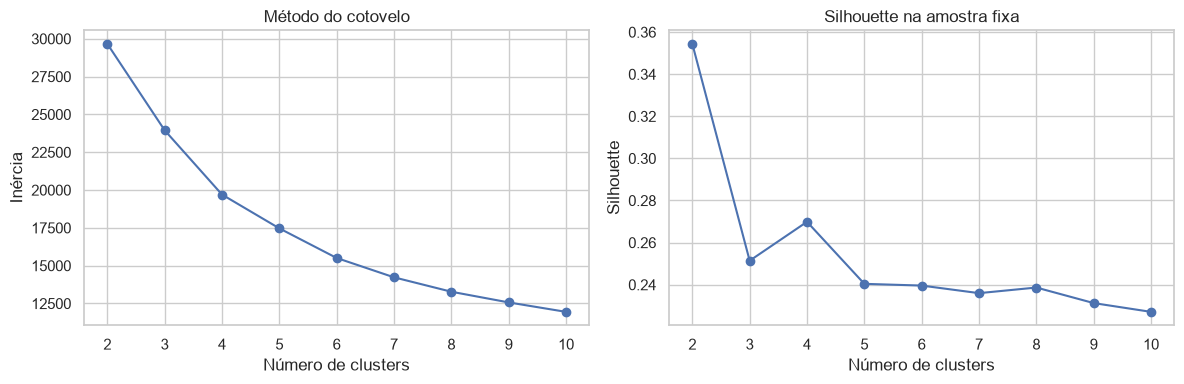

**Decisão:** K = 2, por apresentar a maior silhouette no intervalo testado (0.3544). O gráfico de inércia complementa a leitura; não presumimos um cotovelo inequívoco. A escolha é exploratória e depende das features e da amostra de avaliação.

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
indices_avaliacao = np.sort(rng.choice(len(X_scaled), size=min(2000, len(X_scaled)), replace=False))
def avaliar_silhouette(rotulos_cluster):
    return silhouette_score(X_scaled[indices_avaliacao], rotulos_cluster[indices_avaliacao])

resultados = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    grupos = modelo.fit_predict(X_scaled)
    resultados.append({"K": k, "Inércia": modelo.inertia_,
                       "Silhouette": avaliar_silhouette(grupos)})
resultados = pd.DataFrame(resultados)
display(resultados.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(resultados["K"], resultados["Inércia"], marker="o")
axes[0].set(title="Método do cotovelo", xlabel="Número de clusters", ylabel="Inércia")
axes[1].plot(resultados["K"], resultados["Silhouette"], marker="o")
axes[1].set(title="Silhouette na amostra fixa", xlabel="Número de clusters", ylabel="Silhouette")
plt.tight_layout()
plt.show()
NUMERO_ESCOLHIDO = int(resultados.loc[resultados["Silhouette"].idxmax(), "K"])
display(Markdown(f"**Decisão:** K = {NUMERO_ESCOLHIDO}, por apresentar a maior silhouette "
                 f"no intervalo testado ({resultados['Silhouette'].max():.4f}). "
                 "O gráfico de inércia complementa a leitura; não presumimos um cotovelo inequívoco. "
                 "A escolha é exploratória e depende das features e da amostra de avaliação."))

## 6. K-Means e interpretação dos grupos

,Pedidos
Cluster,
0,6651
1,1349


,order_value_usd,discount_percentage,delivery_distance_km,total_fulfillment_time_min,customer_rating
Cluster,,,,,
0,30.36,12.04,1.69,23.96,4.4
1,29.54,11.28,9.77,55.70,3.7


order_value_usd        discount_percentage         \
                 median    std              median    std   
Cluster                                                     
0                 21.63  26.68                9.97  12.13   
1                 22.07  24.77                7.48  12.03   

        delivery_distance_km       total_fulfillment_time_min         \
                      median   std                     median    std   
Cluster                                                                
0                        1.0  2.01                       23.0   9.60   
1                        9.0  4.21                       52.5  16.32   

        customer_rating        
                 median   std  
Cluster                        
0                   4.5  0.55  
1                   3.5  0.76

order_channel,Dine-In POS,Online Delivery App,Takeaway / Pickup
Cluster,,,
0,0.237,0.587,0.176
1,0.000,1.000,0.000


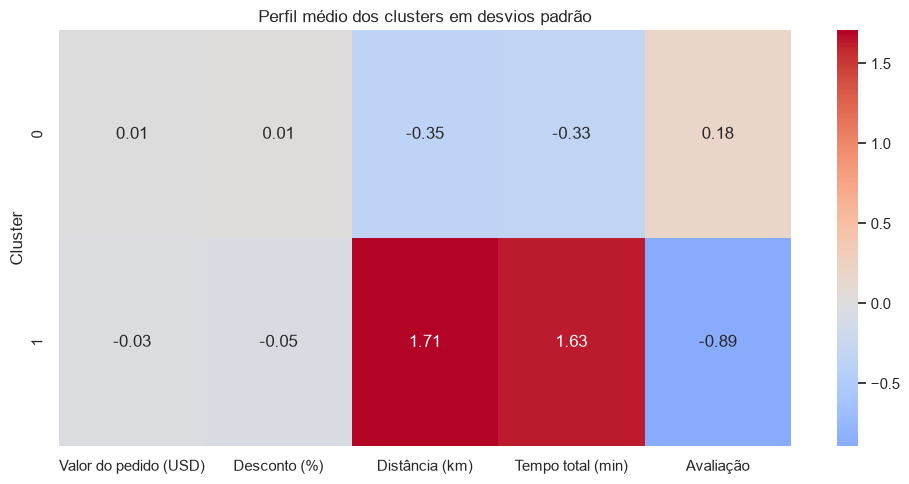

### Grupo 0 — Distância (km) abaixo da média geral; Tempo total (min) abaixo da média geral
6651 pedidos (83.1%). Valor do pedido (USD): 30.36; Desconto (%): 12.04; Distância (km): 1.69; Tempo total (min): 23.96; Avaliação: 4.40. Os destaques são as duas maiores diferenças absolutas em desvios padrão frente à média geral; são descrições relativas, sem julgamento de qualidade.

### Grupo 1 — Distância (km) acima da média geral; Tempo total (min) acima da média geral
1349 pedidos (16.9%). Valor do pedido (USD): 29.54; Desconto (%): 11.28; Distância (km): 9.77; Tempo total (min): 55.70; Avaliação: 3.70. Os destaques são as duas maiores diferenças absolutas em desvios padrão frente à média geral; são descrições relativas, sem julgamento de qualidade.

In [14]:
kmeans = KMeans(n_clusters=NUMERO_ESCOLHIDO, random_state=RANDOM_STATE, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)
df_modelo["Cluster"] = clusters_kmeans
contagem = df_modelo["Cluster"].value_counts().sort_index()
medias = df_modelo.groupby("Cluster")[features].mean()
display(contagem.rename("Pedidos").to_frame())
display(medias.round(2))
display(df_modelo.groupby("Cluster")[features].agg(["median", "std"]).round(2))
display(pd.crosstab(df_modelo["Cluster"], df_modelo["order_channel"], normalize="index").round(3))

perfis_z = pd.DataFrame(kmeans.cluster_centers_, columns=features)
plt.figure(figsize=(10, 5))
sns.heatmap(perfis_z.rename(columns=rotulos), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil médio dos clusters em desvios padrão")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

nomes = {}
for grupo in medias.index:
    perfil = perfis_z.loc[grupo]
    destaques = perfil.abs().nlargest(2).index
    descricao = "; ".join(f"{rotulos[c]} {'acima' if perfil[c] > 0 else 'abaixo'} da média geral"
                          for c in destaques)
    nomes[int(grupo)] = descricao
    valores = "; ".join(f"{rotulos[c]}: {medias.loc[grupo, c]:.2f}" for c in features)
    display(Markdown(f"### Grupo {grupo} — {descricao}\n"
                     f"{contagem.loc[grupo]} pedidos ({100 * contagem.loc[grupo] / len(df_modelo):.1f}%). "
                     f"{valores}. Os destaques são as duas maiores diferenças absolutas em "
                     "desvios padrão frente à média geral; são descrições relativas, sem julgamento de qualidade."))
df_modelo["Perfil"] = df_modelo["Cluster"].map(nomes)

Os números dos clusters são identificadores arbitrários, sem ordem de qualidade.
As descrições usam médias reais dos pedidos e não significam segmentos permanentes
de clientes. A tabela por canal ajuda a distinguir características logísticas
de diferenças associadas ao modo de atendimento.

### Leitura dos resultados observados

O perfil de menor distância e tempo reúne **6.651 pedidos**, com médias de **1,69 km**, **23,96 minutos** e avaliação **4,40**. O perfil de maior distância e tempo reúne **1.349 pedidos**, com **9,77 km**, **55,70 minutos** e avaliação **3,70**.

Todos os pedidos do segundo perfil são por aplicativo; o primeiro mistura os três canais. Os valores médios dos pedidos são próximos (US$ 30,36 e US$ 29,54), indicando diferenças sobretudo logísticas. Essa associação não prova causalidade.

## 7. Visualização com PCA
O PCA projeta as cinco features padronizadas em duas dimensões para visualização.
O agrupamento continua sendo calculado nas cinco dimensões originais padronizadas.
Sobreposições na projeção não descrevem integralmente a separação no espaço original.

Variância explicada: PCA1=40.53%; PCA2=21.70%; total=62.23%


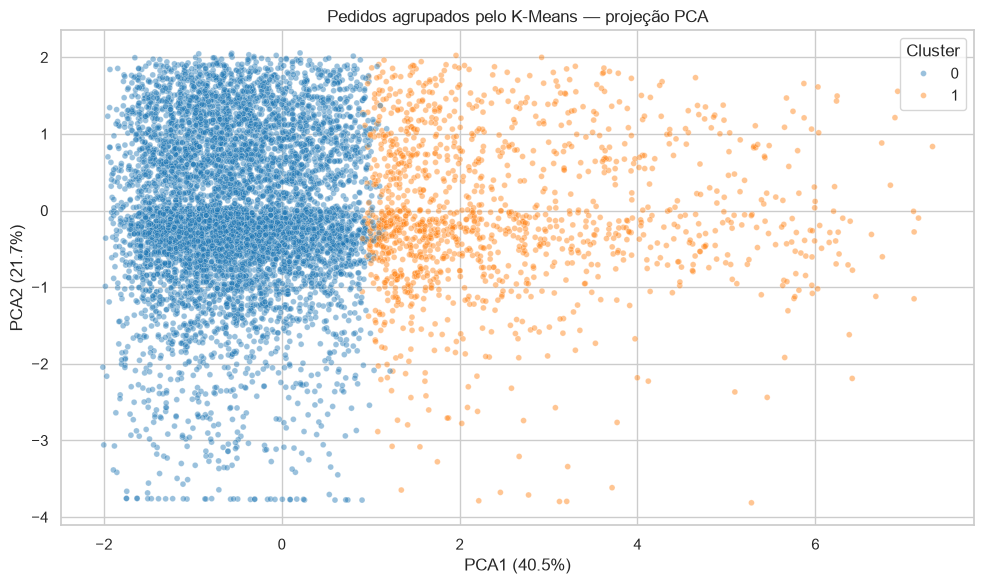

In [15]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
variancia = pca.explained_variance_ratio_
print(f"Variância explicada: PCA1={variancia[0]:.2%}; PCA2={variancia[1]:.2%}; total={variancia.sum():.2%}")
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters_kmeans.astype(str),
                palette="tab10", alpha=.45, s=18)
plt.xlabel(f"PCA1 ({variancia[0]:.1%})")
plt.ylabel(f"PCA2 ({variancia[1]:.1%})")
plt.title("Pedidos agrupados pelo K-Means — projeção PCA")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 8. Comparação com AgglomerativeClustering
Aplicamos ligação Ward e distância euclidiana nas mesmas features padronizadas,
em todos os pedidos e com o mesmo K. Ward combina grupos procurando limitar
o aumento da dispersão interna. O algoritmo é determinístico e não aceita `random_state`.
A comparação avalia esta configuração de Ward, não procura seu melhor K de forma independente.

In [16]:
aglomerativo = AgglomerativeClustering(n_clusters=NUMERO_ESCOLHIDO, linkage="ward")
clusters_agg = aglomerativo.fit_predict(X_scaled)
df_modelo["Cluster_Agglomerative"] = clusters_agg
comparacao = pd.DataFrame({
    "Algoritmo": ["K-Means", "Agglomerative (Ward)"],
    "Número de clusters": [NUMERO_ESCOLHIDO, NUMERO_ESCOLHIDO],
    "Silhouette": [avaliar_silhouette(clusters_kmeans), avaliar_silhouette(clusters_agg)]
})
display(comparacao.round(4))
melhor = comparacao.loc[comparacao["Silhouette"].idxmax(), "Algoritmo"]
diferenca = abs(comparacao["Silhouette"].diff().iloc[-1])
display(Markdown(f"**{melhor}** obteve a maior silhouette nesta comparação. "
                 f"A diferença absoluta foi de **{diferenca:.4f}**. "
                 "Essa diferença é descritiva: não foi realizado teste de significância nem "
                 "análise de estabilidade por reamostragem. Mantemos K-Means como análise "
                 "principal pela simplicidade dos centroides e pelo objetivo didático; "
                 "isso não implica superioridade em qualquer configuração."))

,Algoritmo,Número de clusters,Silhouette
0,K-Means,2,0.3544
1,Agglomerative (Ward),2,0.2592


**K-Means** obteve a maior silhouette nesta comparação. A diferença absoluta foi de **0.0952**. Essa diferença é descritiva: não foi realizado teste de significância nem análise de estabilidade por reamostragem. Mantemos K-Means como análise principal pela simplicidade dos centroides e pelo objetivo didático; isso não implica superioridade em qualquer configuração.

## 9. Interpretação e limites
Os perfis detalhados na seção 6 respondem à pergunta com diferenças relativas de gasto,
promoção, logística e avaliação. O K-Means sempre produz uma partição quando solicitado;
portanto, encontrar médias diferentes não comprova a existência de segmentos naturais.
Silhouette e projeção PCA devem ser lidas junto com o contexto e as distribuições.

Limitações: origem e processo de enriquecimento não documentados; ausência de datas;
mistura de canais; correlação entre distância e tempo; sensibilidade a extremos;
avaliação ordinal tratada como numérica; silhouette aproximada e escolha de K na mesma
amostra usada para comparação. Não há demonstração de causalidade, representatividade
global ou significância estatística. Os valores enriquecidos podem refletir regras
de construção da base em vez de comportamento observado no mercado.

## 10. Conclusão final

In [17]:
resumo_perfis = "\n".join(f"- Grupo {g}: {nome} ({contagem.loc[g]} pedidos)." for g, nome in nomes.items())
display(Markdown(
    f"O objetivo exploratório foi atingido: foram construídos **{NUMERO_ESCOLHIDO} grupos** "
    f"de pedidos com K-Means, selecionados pela maior silhouette entre K=2 e K=10.\n\n"
    f"Os padrões encontrados foram:\n\n{resumo_perfis}\n\n"
    f"**{melhor}** apresentou a maior silhouette na comparação das configurações testadas "
    f"(diferença de {diferenca:.4f}). O PCA preservou {variancia.sum():.2%} da variância "
    "em duas dimensões. Os resultados indicam perfis relativos, sem comprovar segmentos "
    "naturais estáveis. Como próximos passos, sugerimos verificar a fonte e as regras de "
    "enriquecimento, repetir a análise só com entregas, testar a retirada de uma das "
    "features logísticas correlacionadas e avaliar estabilidade com outras sementes e amostras."
))

O objetivo exploratório foi atingido: foram construídos **2 grupos** de pedidos com K-Means, selecionados pela maior silhouette entre K=2 e K=10.

Os padrões encontrados foram:

- Grupo 0: Distância (km) abaixo da média geral; Tempo total (min) abaixo da média geral (6651 pedidos).
- Grupo 1: Distância (km) acima da média geral; Tempo total (min) acima da média geral (1349 pedidos).

**K-Means** apresentou a maior silhouette na comparação das configurações testadas (diferença de 0.0952). O PCA preservou 62.23% da variância em duas dimensões. Os resultados indicam perfis relativos, sem comprovar segmentos naturais estáveis. Como próximos passos, sugerimos verificar a fonte e as regras de enriquecimento, repetir a análise só com entregas, testar a retirada de uma das features logísticas correlacionadas e avaliar estabilidade com outras sementes e amostras.